# 实验四：多层感知机（改进 MLP）

按照 [参考实验](https://github.com/Guyudong1/CV_exp/tree/main/4th.exp) 完成 MNIST 分类。使用完整的 60,000 张训练图和 10,000 张测试图，每张图为 28×28 灰度图。模型输出 10 个类别的 logits，训练使用交叉熵损失。

从仓库根目录或 `exp4` 目录启动，选择安装了 `requirements.txt` 的 Python 内核，按顺序运行全部单元格。完整源码位于 `experiment.py`。已有结果时默认展示记录，并重新加载权重核对测试预测；将 `RETRAIN` 改成 `True` 可重新训练 10 轮。首次运行缺少结果时会自动训练。数据缓存放在 `.local/data`。

本 Notebook 对应 `improved` 模型，另一组在 `code.ipynb`。两组均完成后会生成 `result/comparison.png` 和汇总指标。


In [1]:
from pathlib import Path
import csv
import inspect
import json
import sys

from IPython.display import Image, Markdown, display

cwd = Path.cwd()
exp_dir = cwd / "exp4" if (cwd / "exp4" / "experiment.py").is_file() else cwd
assert (exp_dir / "experiment.py").is_file(), "请从仓库根目录或 exp4 目录启动。"
sys.path.insert(0, str(exp_dir)) if str(exp_dir) not in sys.path else None
from experiment import (
    ImprovedMLP, configure, load_data, train_model, evaluate, run_experiment,
    torch, DataLoader,
)

MODEL_NAME = "improved"
RETRAIN = False
result_dir = exp_dir / "result" / MODEL_NAME


C:\Users\27247\AppData\Local\Programs\Python\Python312\Lib\site-packages\triton\windows_utils.py:465: UserWarning: Failed to find CUDA. Install CUDA Toolkit (https://developer.nvidia.com/cuda-downloads) or set CUDA_HOME / CUDA_PATH environment variable.
  warnings.warn("Failed to find CUDA."


## 1. 数据与预处理

MNIST 沿用官方训练集、测试集划分，不混合两个集合。像素从 `uint8` 转为 `float32`，再除以 255，得到 `[0, 1]` 数值。一次转换全部图像与逐张调用无增强的 `ToTensor()` 等价。前向传播将图像展开成 784 维向量。

测试集按原顺序遍历。网络配置和训练轮数按参考代码预先确定，测试结果不参与训练和模型选择。下图选取训练集中每个数字第一次出现的位置，选图不会消耗训练加载器的随机序列。


In [2]:
device = configure(seed=2026)
train_set, test_set, fingerprints = load_data(exp_dir / ".local" / "data")
print("设备：", device)
print("训练集：", train_set.tensors[0].shape)
print("测试集：", test_set.tensors[0].shape)
print("像素范围：", float(train_set.tensors[0].min()), float(train_set.tensors[0].max()))
print("训练像素类型：", train_set.tensors[0].dtype)
print("数据文件 SHA-256：", json.dumps(fingerprints, indent=2))


设备： cuda
训练集： torch.Size([60000, 1, 28, 28])
测试集： torch.Size([10000, 1, 28, 28])
像素范围： 0.0 1.0
训练像素类型： torch.float32
数据文件 SHA-256： {
  "train-images-idx3-ubyte": "ba891046e6505d7aadcbbe25680a0738ad16aec93bde7f9b65e87a2fc25776db",
  "train-labels-idx1-ubyte": "65a50cbbf4e906d70832878ad85ccda5333a97f0f4c3dd2ef09a8a9eef7101c5",
  "t10k-images-idx3-ubyte": "0fa7898d509279e482958e8ce81c8e77db3f2f8254e26661ceb7762c4d494ce7",
  "t10k-labels-idx1-ubyte": "ff7bcfd416de33731a308c3f266cc351222c34898ecbeaf847f06e48f7ec33f2"
}


## 2. 网络结构与优化器

改进模型包含三个隐藏层和一个输出层：`784 → 256 → 128 → 64 → 10`。三个隐藏层均使用 BatchNorm 和 GELU，前两个隐藏层后使用 `Dropout(0.3)`。优化器为 Adam，学习率为 `0.001`。BatchNorm 的参数与运行统计、Dropout 的模式均随 `train()` 和 `eval()` 切换。

In [3]:
print(inspect.getsource(ImprovedMLP))
model = ImprovedMLP()
print("可训练参数：", sum(p.numel() for p in model.parameters()))


class ImprovedMLP(nn.Module):
    """三个隐藏层，BatchNorm、GELU 和前两层后的 Dropout。"""

    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(784, 256)
        self.bn1 = nn.BatchNorm1d(256)
        self.fc2 = nn.Linear(256, 128)
        self.bn2 = nn.BatchNorm1d(128)
        self.fc3 = nn.Linear(128, 64)
        self.bn3 = nn.BatchNorm1d(64)
        self.fc4 = nn.Linear(64, 10)
        self.drop = nn.Dropout(0.3)
        self.act = nn.GELU()

    def forward(self, x):
        x = x.flatten(1)
        x = self.drop(self.act(self.bn1(self.fc1(x))))
        x = self.drop(self.act(self.bn2(self.fc2(x))))
        x = self.act(self.bn3(self.fc3(x)))
        return self.fc4(x)

可训练参数： 243658


## 3. 训练与损失记录

批量大小设为 `2048`，训练 `10` 轮，随机种子为 `2026`。两组分别重置同一个种子，并使用独立但同种子的训练加载器，使每轮打乱的样本顺序一致。每批依次清空梯度、前向传播、计算交叉熵、反向传播和更新参数。

每轮损失按样本数量加权。在线训练准确率汇总本轮各批在更新前的预测，模型处于训练模式，因此与最终模型在 `eval()` 模式下的准确率含义不同。改进模型的 Dropout 在训练时启用，也会影响这项统计。


def train_model(model, loader, optimizer, device, epochs, name):
    history = []
    for epoch in range(1, epochs + 1):
        model.train()
        loss_sum, correct, count = 0.0, 0, 0
        start = time.perf_counter()
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad(set_to_none=True)
            logits = model(x)
            loss = F.cross_entropy(logits, y)
            if not torch.isfinite(loss):
                raise RuntimeError(f"{name} 第 {epoch} 轮损失非有限值。")
            loss.backward()
            optimizer.step()
            # 按样本加权，末批不足 batch_size 时也有正确的权重。
            loss_sum += loss.item() * len(y)
            correct += int((logits.argmax(1) == y).sum().item())
            count += len(y)
        row = {"epoch": epoch, "train_loss": loss_sum / count,
               "online_train_accuracy": correct / count,
               "seconds": time.perf_counter() - start}
        history.append(row)
        print(f"{name:8s} 

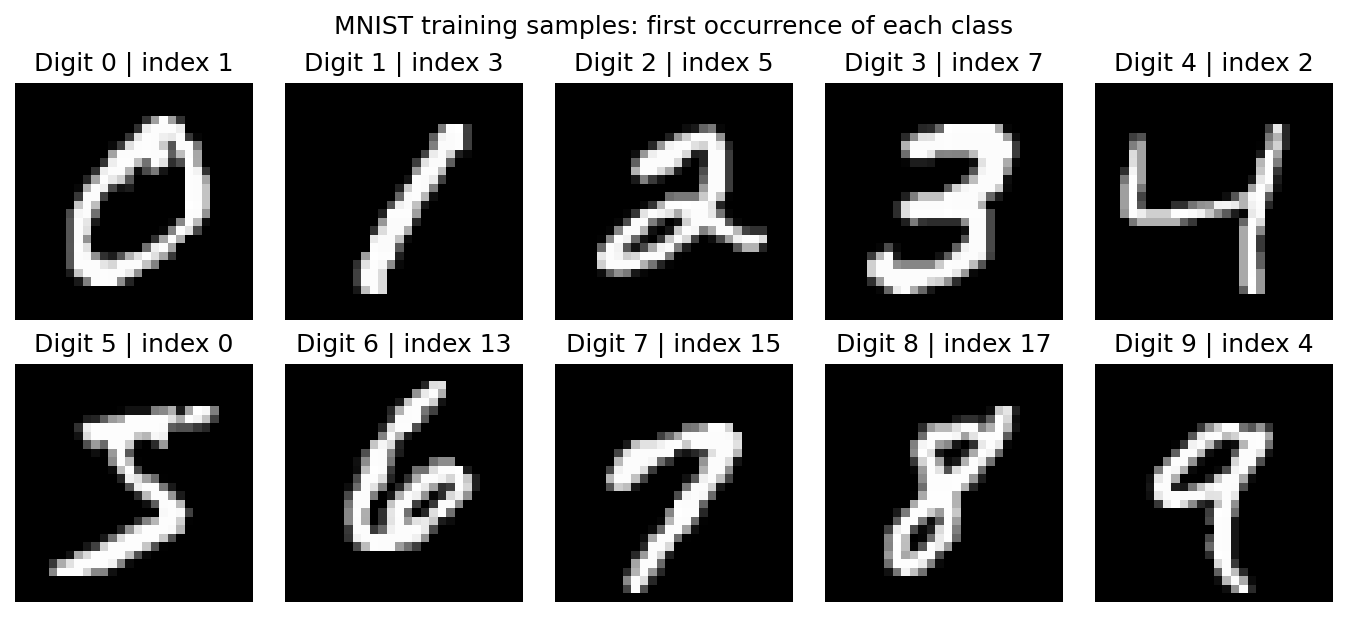

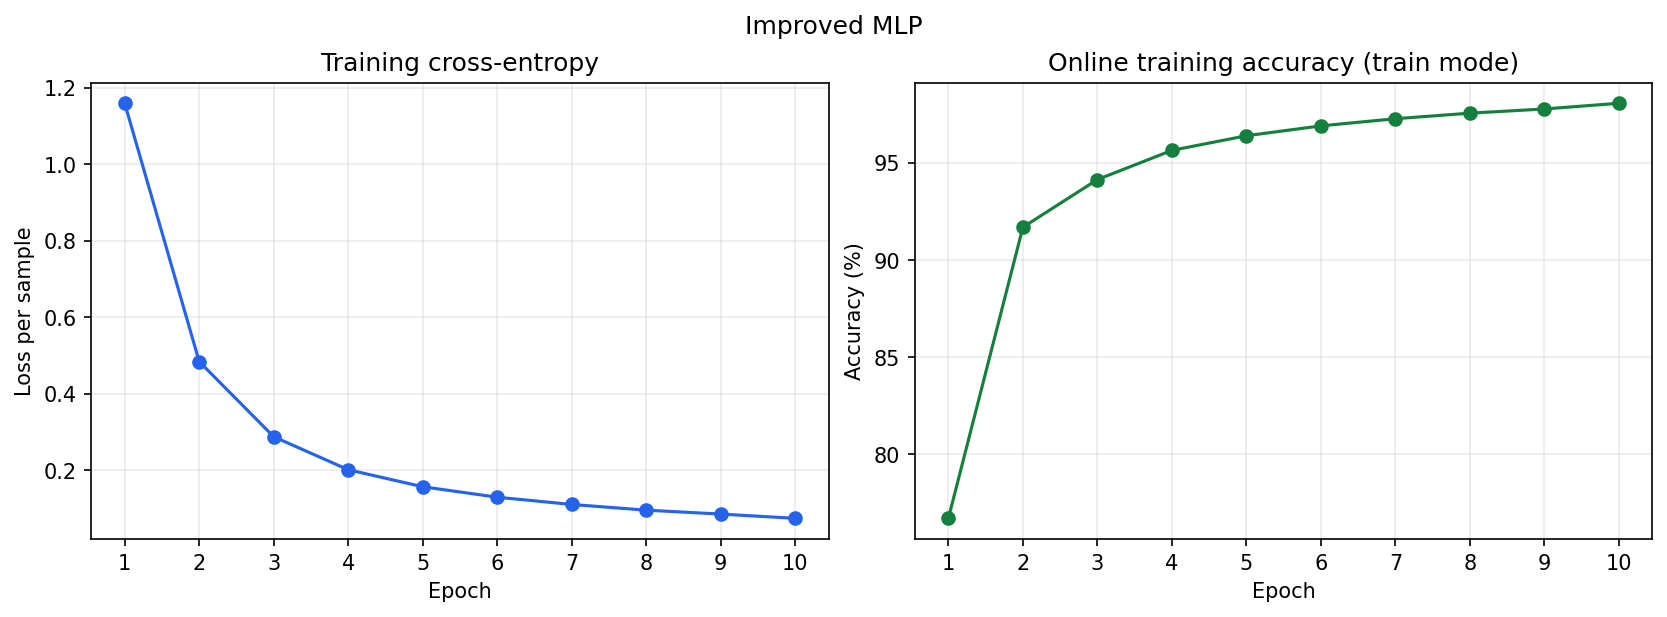

In [4]:
print(inspect.getsource(train_model))
if RETRAIN or not (result_dir / "summary.json").is_file():
    run_experiment(model_name=MODEL_NAME, epochs=10, batch_size=2048,
                   seed=2026, data_dir=exp_dir / ".local" / "data",
                   output_dir=exp_dir / "result")
summary = json.loads((result_dir / "summary.json").read_text(encoding="utf-8"))
assert summary["dataset_sha256"] == fingerprints
assert (summary["epochs"], summary["batch_size"], summary["seed"]) == (10, 2048, 2026)
with (result_dir / "history.csv").open(encoding="utf-8", newline="") as stream:
    history = list(csv.DictReader(stream))
for row in history:
    print(f"Epoch {int(row['epoch']):2d}: loss={float(row['train_loss']):.6f}, "
          f"online accuracy={float(row['online_train_accuracy']):.2%}")
display(Image(filename=str(exp_dir / "result" / "samples.png"), width=800))
display(Image(filename=str(result_dir / "training_curves.png"), width=900))


## 4. 独立加载权重并测试

模型权重保存在 `model.pth`，只包含 `state_dict`。重新建立模型、严格加载权重，再切换到 `eval()` 并关闭梯度计算，使用全部 10,000 张测试图推理。损失为所有测试样本交叉熵的平均值，准确率为正确预测数除以测试样本数。

此处同时核对权重摘要、保存的逐样本预测和混淆矩阵，确保报告与可加载模型对应。


In [5]:
import hashlib
import numpy as np

weights_path = result_dir / "model.pth"
assert hashlib.sha256(weights_path.read_bytes()).hexdigest() == summary["model_sha256"]
model = ImprovedMLP().to(device)
model.load_state_dict(torch.load(weights_path, map_location=device, weights_only=True), strict=True)
test_loader = DataLoader(test_set, batch_size=2048, shuffle=False, num_workers=0)
metrics, cm, classes, labels, predictions = evaluate(model, test_loader, device)
with (result_dir / "test_predictions.csv").open(encoding="utf-8", newline="") as stream:
    saved = list(csv.DictReader(stream))
assert np.array_equal(labels, [int(row["true_label"]) for row in saved])
assert np.array_equal(predictions, [int(row["prediction"]) for row in saved])
assert np.array_equal(cm, summary["confusion_matrix"])
assert metrics["test_accuracy"] == summary["metrics"]["test_accuracy"]
assert abs(metrics["test_loss"] - summary["metrics"]["test_loss"]) < 1e-5
print(json.dumps(metrics, ensure_ascii=False, indent=2))
print("权重加载和全部测试预测核对通过。")


{
  "test_loss": 0.06767566871643066,
  "test_accuracy": 0.9801,
  "correct": 9801,
  "incorrect": 199,
  "macro_f1": 0.9799711885908697
}
权重加载和全部测试预测核对通过。


## 5. 混淆矩阵与分类统计

混淆矩阵的行是真实数字，列是预测数字。对角线计数之和等于正确数，其余位置为误分类。各行样本数由官方测试集决定，各类召回率为本类正确数除以本类真实样本数。宏平均 F1 为 10 类 F1 的算术平均。


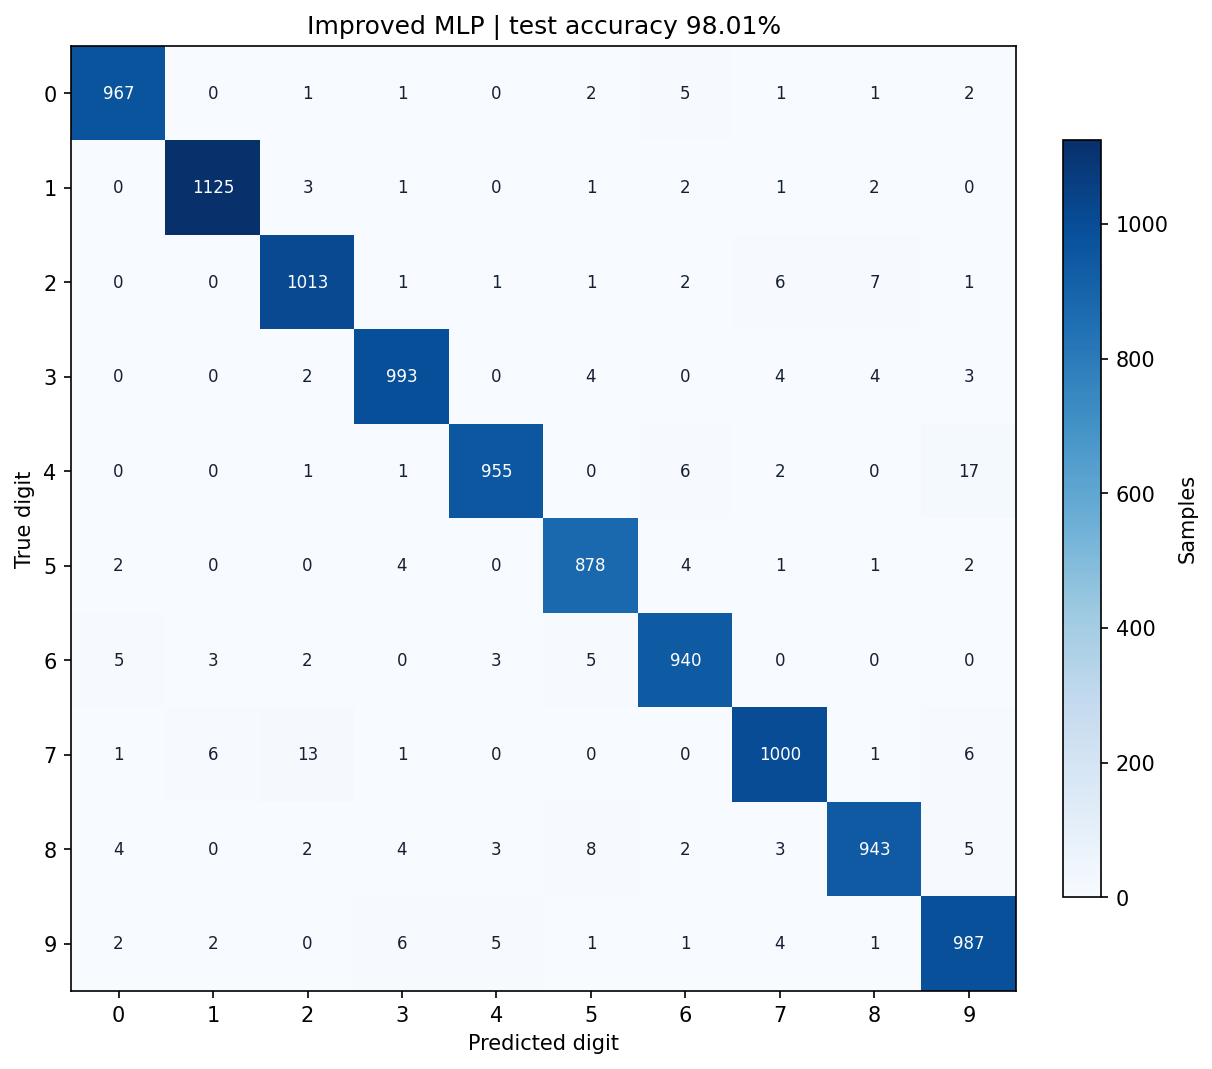

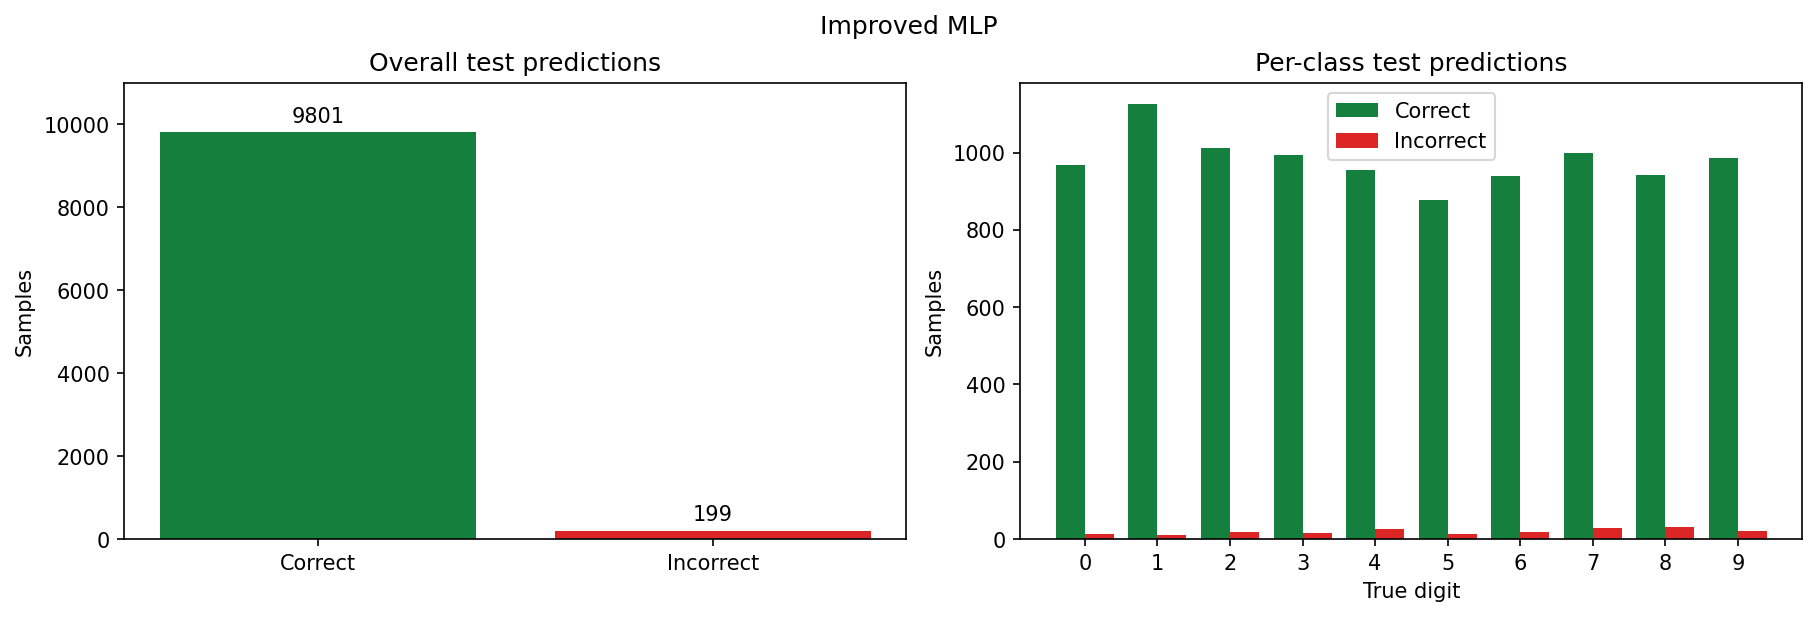

| 数字 | 样本数 | 正确 | 错误 | 精确率 | 召回率 | F1 |
| --- | ---: | ---: | ---: | ---: | ---: | ---: |
| 0 | 980 | 967 | 13 | 98.57% | 98.67% | 0.9862 |
| 1 | 1135 | 1125 | 10 | 99.03% | 99.12% | 0.9908 |
| 2 | 1032 | 1013 | 19 | 97.69% | 98.16% | 0.9792 |
| 3 | 1010 | 993 | 17 | 98.12% | 98.32% | 0.9822 |
| 4 | 982 | 955 | 27 | 98.76% | 97.25% | 0.9800 |
| 5 | 892 | 878 | 14 | 97.56% | 98.43% | 0.9799 |
| 6 | 958 | 940 | 18 | 97.71% | 98.12% | 0.9792 |
| 7 | 1028 | 1000 | 28 | 97.85% | 97.28% | 0.9756 |
| 8 | 974 | 943 | 31 | 98.23% | 96.82% | 0.9752 |
| 9 | 1009 | 987 | 22 | 96.48% | 97.82% | 0.9715 |


In [6]:
display(Image(filename=str(result_dir / "confusion_matrix.png"), width=700))
display(Image(filename=str(result_dir / "prediction_statistics.png"), width=900))
table = "| 数字 | 样本数 | 正确 | 错误 | 精确率 | 召回率 | F1 |\n"
table += "| --- | ---: | ---: | ---: | ---: | ---: | ---: |\n"
for row in classes:
    table += (f"| {row['digit']} | {row['support']} | {row['correct']} | {row['incorrect']} | "
              f"{row['precision']:.2%} | {row['recall']:.2%} | {row['f1']:.4f} |\n")
display(Markdown(table))


## 6. 预测示例与错误分析

第一张图固定展示测试集前 12 张图。第二张图按原索引取前 12 个错误，便于复查，不将这些错误视为全部错误的随机代表。标题中 `true` 为真实数字，`pred` 为预测数字。


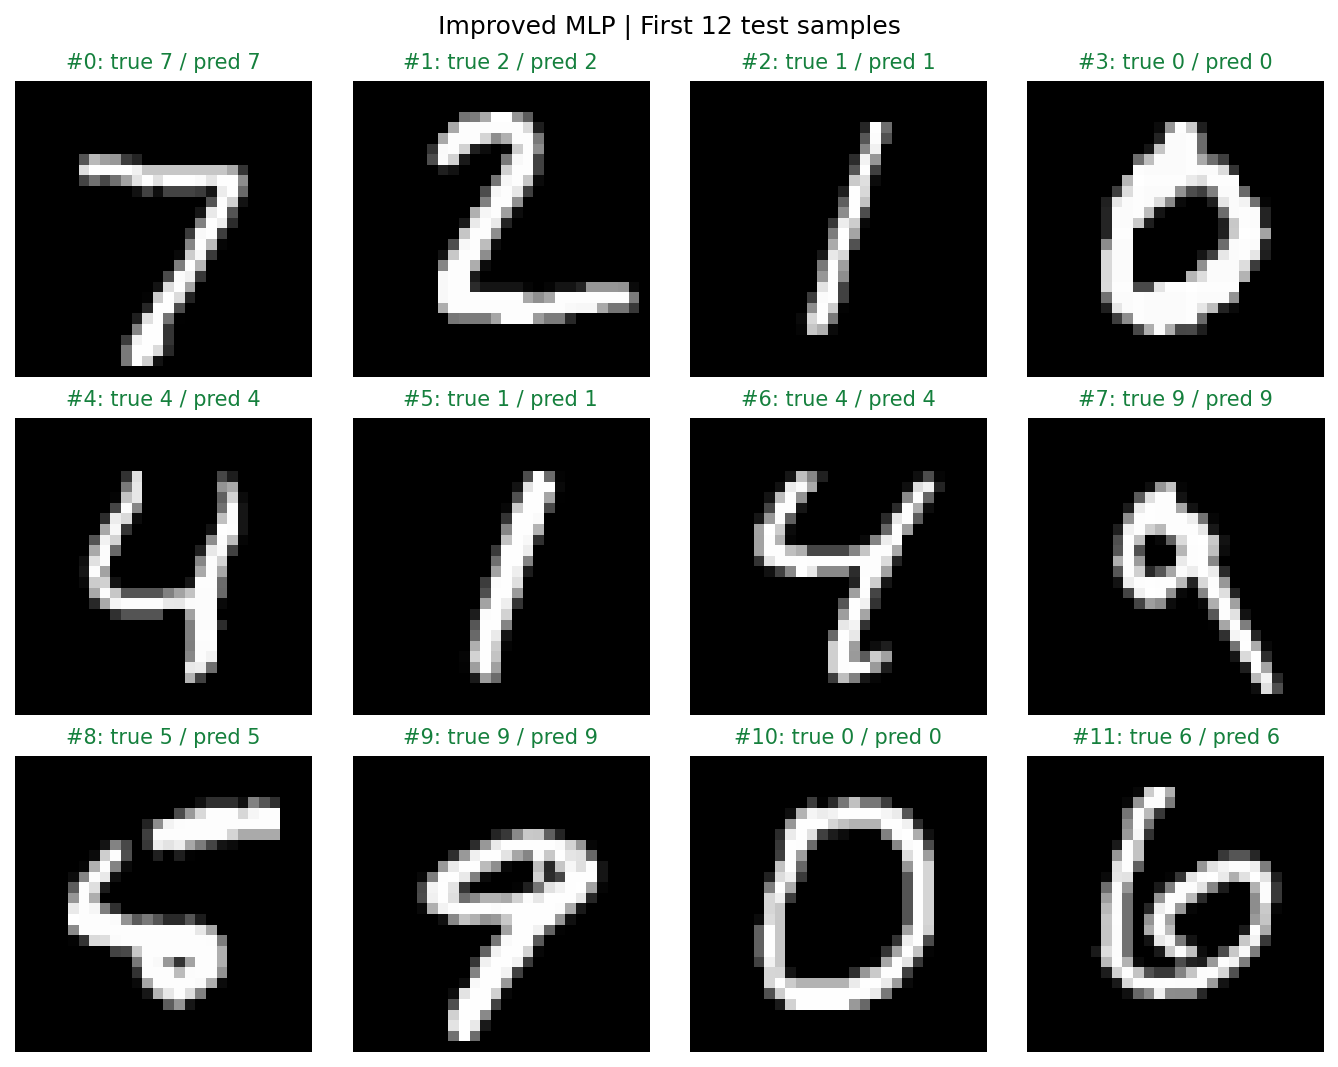

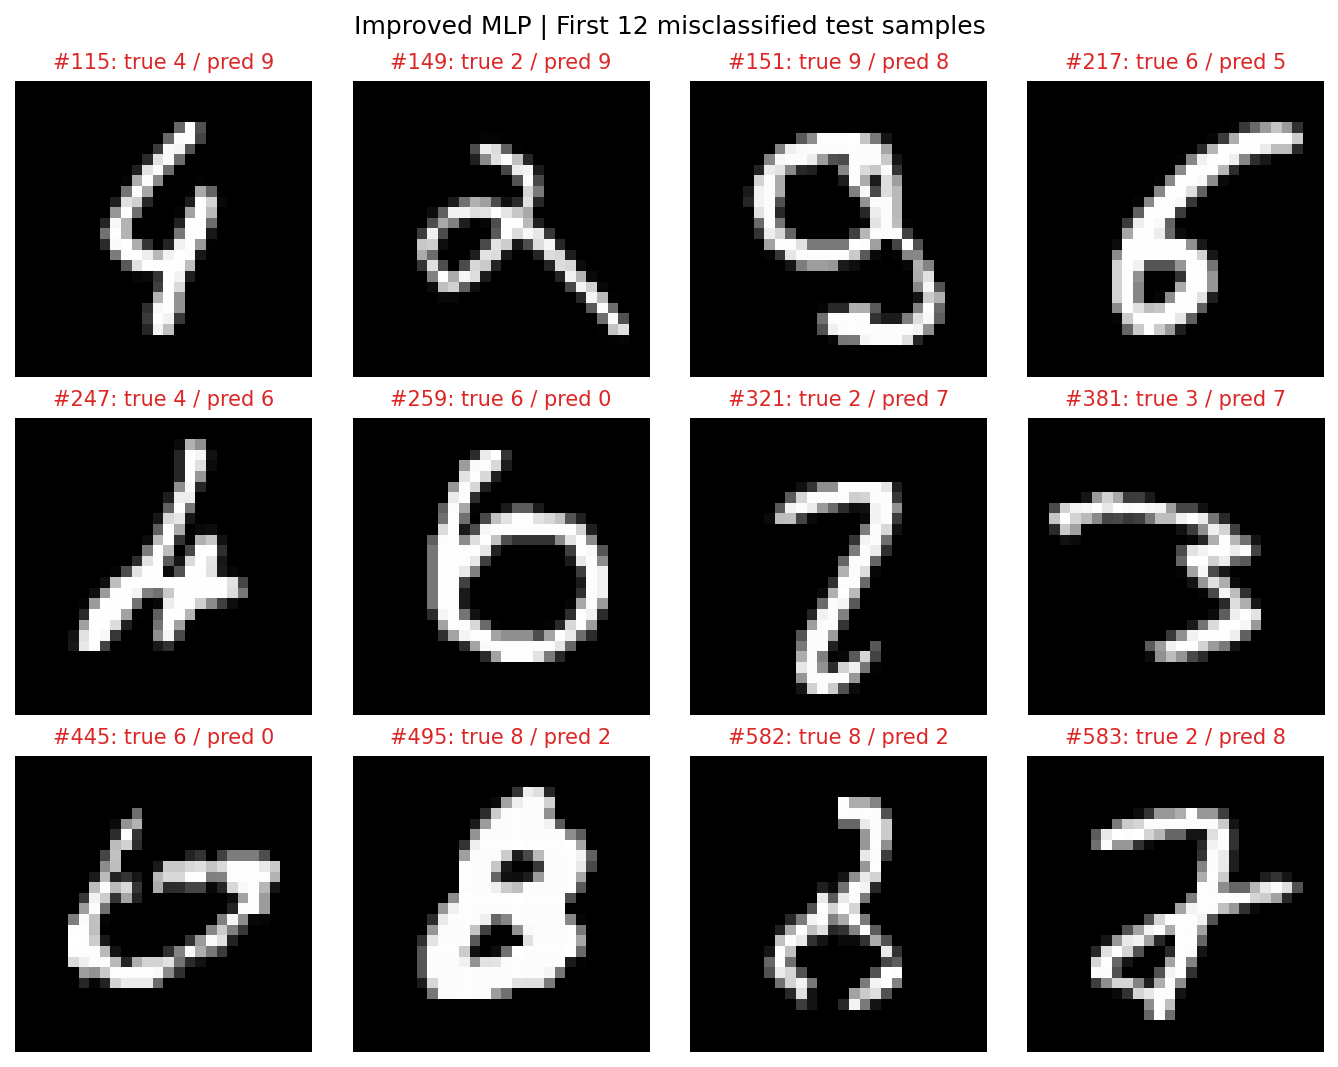

In [7]:
display(Image(filename=str(result_dir / "predictions.png"), width=800))
display(Image(filename=str(result_dir / "errors.png"), width=800))


## 7. 两组比较

两组使用相同训练预算，最终测试集只用于评价。改进组同时改变隐藏层宽度与深度、激活函数、归一化、随机失活和优化器，结果只能说明这套配置的整体差异。判断某一个因素的贡献需要单因素消融实验。一次固定种子的结果也不能说明跨随机种子的稳定性。


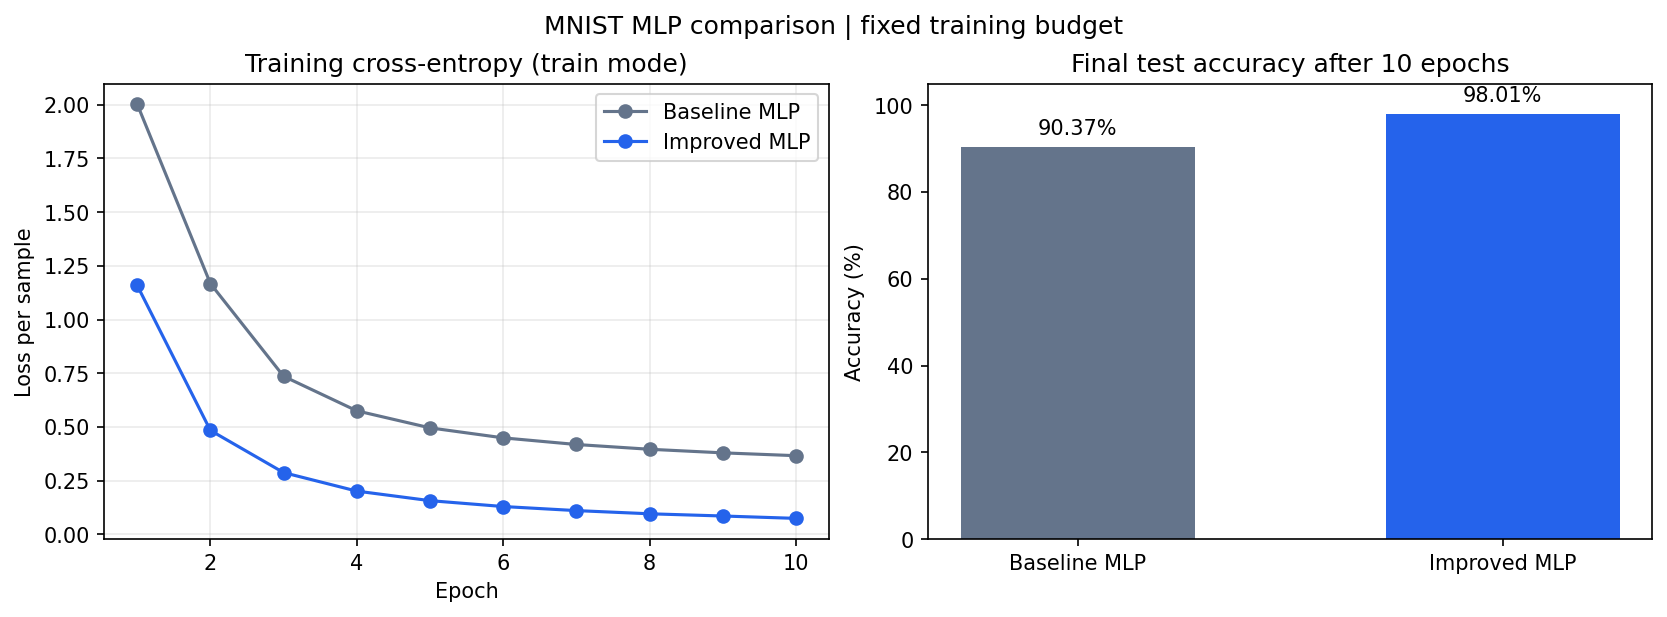

baseline: accuracy=90.37%, loss=0.343137
improved: accuracy=98.01%, loss=0.067676
准确率差：7.64 个百分点


In [8]:
comparison = exp_dir / "result" / "comparison.png"
if comparison.is_file():
    display(Image(filename=str(comparison), width=900))
    combined = json.loads((exp_dir / "result" / "summary.json").read_text(encoding="utf-8"))
    for experiment in combined["experiments"]:
        m = experiment["metrics"]
        print(f"{experiment['model']}: accuracy={m['test_accuracy']:.2%}, loss={m['test_loss']:.6f}")
    print(f"准确率差：{combined['accuracy_gain_percentage_points']:.2f} 个百分点")
else:
    print("另一组尚未完成。运行另一份 Notebook 或 python exp4/experiment.py 后查看对比。")
